# TIỂU LUẬN: BÁO CÁO PHÂN TÍCH VÀ KIỂM TOÁN CHẤT LƯỢNG DỮ LIỆU
## ĐỀ TÀI: GIÁM ĐỊNH VÀ PHÁT HIỆN BẤT THƯỜNG TRONG CHI TRẢ BẢO HIỂM Y TẾ MEDICARE
* **Học phần:** Xử lý và Khai phá Dữ liệu / Data Preprocessing & Analytics
* **Bộ dữ liệu:** Hồ sơ Bồi thường Chi phí Y tế Ngoại trú (Outpatient) & Nội trú (Inpatient)
* **Nhóm thực hiện:** Nhóm 6
* **Trưởng nhóm:** Phan Thị Quế Trân (MSSV: 2521001108)
* **Thời gian thực hiện:** Năm 2026


---
# PHẦN 1: BỐI CẢNH KINH DOANH & QUY TRÌNH PHÁT SINH DỮ LIỆU

### 1.1. Bối cảnh kinh doanh (Business Context)
Trong lĩnh vực bảo hiểm y tế (Healthcare Insurance), đặc biệt là chương trình bảo hiểm y tế công Medicare (Hoa Kỳ), việc thanh toán chi phí khám chữa bệnh diễn ra giữa cơ quan bảo hiểm và các cơ sở y tế (Healthcare Providers gồm Bệnh viện, Phòng khám, Trung tâm y tế) với quy mô hàng trăm tỷ USD mỗi năm. 

Do khối lượng hồ sơ bồi thường (Claims) phát sinh hàng ngày là cực kỳ lớn, quỹ bảo hiểm luôn đứng trước nguy cơ **trục lợi và gian lận bảo hiểm y tế (Healthcare Fraud & Abuse)**. Các hành vi gian lận điển hình gồm:
* **Kê khống viện phí (`InscClaimAmtReimbursed`):** Yêu cầu bồi hoàn số tiền lớn hơn thực tế chi phí điều trị.
* **Gian lận dịch vụ y tế:** Chỉ định các thủ thuật phẫu thuật phức tạp không cần thiết (`ClmProcedureCode`).
* **Lạm dụng mã chẩn đoán (Upcoding):** Gán thêm các mã chẩn đoán bệnh lý nặng (`ClmDiagnosisCode`) để nâng khung thanh toán bảo hiểm.
* **Kéo dài ngày nằm viện (`Length of Stay`):** Giữ bệnh nhân điều trị nội trú lâu hơn mức cần thiết để thu tiền giường và tiền dịch vụ.

Bộ dữ liệu nghiên cứu phản ánh hai nghiệp vụ khám chữa bệnh cốt lõi:
1. **Dữ liệu Ngoại trú (Outpatient Claims):** Bệnh nhân đến khám lâm sàng, làm xét nghiệm, chụp chiếu, nhận đơn thuốc và ra về trong ngày. Không phát sinh lưu trú qua đêm tại bệnh viện.
2. **Dữ liệu Nội trú (Inpatient Claims):** Bệnh nhân có chỉ định nhập viện, lưu trú qua đêm để điều trị nội khoa hoặc thực hiện phẫu thuật từ 1 ngày đến nhiều tuần.

### 1.2. Phòng ban quản lý và Quy trình phát sinh dữ liệu
Dữ liệu được hình thành và lưu chuyển qua chuỗi quy trình phối hợp khép kín giữa Bệnh viện và Cơ quan Bảo hiểm Y tế:

1. **Phòng Tiếp đón & Đăng ký Khám (Admissions / Front Desk):**
   * Tiếp nhận thông tin thẻ bảo hiểm của bệnh nhân, định danh bằng mã `BeneID` (Beneficiary ID).
   * Ghi nhận ngày giờ bắt đầu khám (`ClaimStartDt`) hoặc ngày chính thức nhập viện nội trú (`AdmissionDt`).
2. **Khoa Khám bệnh & Các Khoa Lâm sàng / Phẫu thuật (Clinical & Surgical Departments):**
   * Bác sĩ điều trị chính (`AttendingPhysician`) thăm khám, xác định mã chẩn đoán ban đầu khi vào viện (`ClmAdmitDiagnosisCode`) và chẩn đoán xác định (`ClmDiagnosisCode_1` đến `_10` theo chuẩn quốc tế ICD-9/10).
   * Nếu có can thiệp ngoại khoa, bác sĩ phẫu thuật chính (`OperatingPhysician`) cùng bác sĩ phụ mổ (`OtherPhysician`) ghi nhận các mã thủ thuật y tế (`ClmProcedureCode_1` đến `_6`).
   * Khi hoàn tất điều trị, bác sĩ ký lệnh xuất viện (`DischargeDt`).
3. **Phòng Kế toán Viện phí & Giám định BHYT (Billing & Medical Coding Department):**
   * Tổng hợp toàn bộ bảng kê chi phí theo danh mục dịch vụ kỹ thuật và thuốc.
   * Tính toán số tiền khấu trừ mà bệnh nhân tự chi trả tại viện (`DeductibleAmtPaid`).
   * Tạo mã hồ sơ bồi thường duy nhất (`ClaimID`), xác định mã cơ sở y tế yêu cầu thanh toán (`Provider`).
   * Gửi hồ sơ điện tử (Electronic Claim Submission) tới Cổng giám định BHYT CMS để yêu cầu cơ quan bảo hiểm chi trả bồi thường (`InscClaimAmtReimbursed`).


---
# PHẦN 2: KIẾN TRÚC & TỪ ĐIỂN DỮ LIỆU (DATA DICTIONARY)

### 2.1. Kiến trúc tổng thể và Các cột khóa liên kết (Relational Keys)
Dữ liệu giám định chi phí bồi thường bảo hiểm y tế Medicare được thiết kế theo mô hình quan hệ giữa hai bảng thực thể chính: **Hồ sơ Khám Ngoại trú (Outpatient Claims)** và **Hồ sơ Điều trị Nội trú (Inpatient Claims)**. Cả hai bảng chia sẻ chung một kiến trúc định danh giao dịch chuẩn:

* **Khóa chính (Primary Key - PK):** `ClaimID` – Mã định danh duy nhất cho từng lượt hồ sơ yêu cầu bồi thường bảo hiểm. Mỗi `ClaimID` đại diện cho một giao dịch viện phí độc lập, không được phép trùng lặp hoặc để trống.
* **Khóa ngoại liên kết (Foreign Keys - FK):**
  * `BeneID` (Beneficiary ID): Mã định danh bệnh nhân thụ hưởng bảo hiểm. Cột này liên kết đến bảng danh mục nhân khẩu học người bệnh (chứa thông tin giới tính, độ tuổi, tiền sử bệnh mãn tính). Một `BeneID` có thể xuất hiện nhiều lần (quan hệ $1 - N$) tương ứng với nhiều đợt khám/chữa bệnh khác nhau.
  * `Provider`: Mã định danh cơ sở khám chữa bệnh (Bệnh viện, Trung tâm y tế, Phòng khám). Cột này liên kết đến danh mục cơ sở y tế thụ hưởng chi phí bồi thường và là đối tượng trọng tâm được giám định để phát hiện gian lận.

```
       [Bảng Nhân khẩu học Bệnh nhân]
                   │ (1)
                   │  BeneID
                   ▼ (N)
 ┌──────────────────────────────────────────────────────────────┐
 │               HỒ SƠ BỒI THƯỜNG BẢO HIỂM Y TẾ                 │
 │  • Ngoại trú: Outpatient Claims (517,737 dòng, 27 cột)       │
 │  • Nội trú: Inpatient Claims (9,551 dòng, 30 cột)            │
 │    [ClaimID: Khóa chính duy nhất của giao dịch]             │
 └──────────────────────────────────────────────────────────────┘
                   ▲ (N)
                   │  Provider
                   │ (1)
        [Danh mục Cơ sở Y tế / Bệnh viện]
```

---

### 2.2. Bảng Từ Điển Dữ Liệu Chi Tiết (Full Data Dictionary - 30 Biến)

Dưới đây là từ điển dữ liệu chuẩn hóa toàn bộ **30 biến thuộc tính** xuất hiện trong 2 bộ dữ liệu, phân loại chi tiết theo nghiệp vụ bảo hiểm y tế:

| STT | Tên Biến | Ý Nghĩa Thực Tế Nghiệp Vụ | Đơn Vị / Định Dạng | Kiểu Dữ Liệu (Lý thuyết / Thực tế) | Xuất Hiện Tại Bảng | Phân Loại Vai Trò | Tính Chất Dữ Liệu & Ràng Buộc Nghiệp Vụ |
| :---: | :--- | :--- | :---: | :---: | :---: | :---: | :--- |
| **1** | `BeneID` | Mã định danh người thụ hưởng bảo hiểm (Bệnh nhân) | Chuỗi định danh | String / Object | Cả 2 bảng | Khóa ngoại (FK) | Bắt buộc có. Thiếu là lỗi dữ liệu nghiêm trọng cần loại bỏ. |
| **2** | `ClaimID` | Mã hồ sơ yêu cầu chi trả bồi thường BHYT | Chuỗi định danh | String / Object | Cả 2 bảng | Khóa chính (PK) | Định danh duy nhất cho từng giao dịch bồi thường. |
| **3** | `ClaimStartDt` | Ngày bắt đầu đợt yêu cầu bồi thường BHYT | YYYY-MM-DD | Datetime / Object | Cả 2 bảng | Biến thời gian (Feature) | Bắt buộc <= `ClaimEndDt`. |
| **4** | `ClaimEndDt` | Ngày kết thúc đợt yêu cầu bồi thường BHYT | YYYY-MM-DD | Datetime / Object | Cả 2 bảng | Biến thời gian (Feature) | Bắt buộc >= `ClaimStartDt`. |
| **5** | `Provider` | Mã cơ sở y tế / Bệnh viện tiếp nhận điều trị | Chuỗi định danh | String / Object | Cả 2 bảng | Khóa ngoại (FK) | Đơn vị yêu cầu bảo hiểm chi trả tiền. |
| **6** | `InscClaimAmtReimbursed` | Số tiền bảo hiểm chấp thuận thanh toán bồi hoàn | USD ($) | Float64 / Object | Cả 2 bảng | **Biến mục tiêu (Target)** | Tiền bảo hiểm trả. Giá trị phải >= 0 (không thể âm). |
| **7** | `DeductibleAmtPaid` | Số tiền khấu trừ người bệnh phải tự chi trả | USD ($) | Float64 / Object | Cả 2 bảng | Biến tài chính (Feature) | Tiền đồng chi trả tại viện. Giá trị phải >= 0. |
| **8** | `AttendingPhysician` | Mã bác sĩ điều trị / phụ trách chuyên môn chính | Chuỗi định danh | String / Object | Cả 2 bảng | Biến nhân sự (Feature) | Bác sĩ khám lâm sàng và ký xác nhận bệnh án. |
| **9** | `OperatingPhysician` | Mã bác sĩ phẫu thuật chính thực hiện can thiệp | Chuỗi định danh | String / Object | Cả 2 bảng | Biến nhân sự (Feature) | Chỉ phát sinh khi có can thiệp mổ/thủ thuật. |
| **10** | `OtherPhysician` | Mã bác sĩ phụ tá / bác sĩ hội chẩn chuyên khoa | Chuỗi định danh | String / Object | Cả 2 bảng | Biến nhân sự (Feature) | Bác sĩ hỗ trợ chuyên môn cho ca bệnh phức tạp. |
| **11** | `AdmissionDt` | Ngày bệnh nhân chính thức làm thủ tục nhập viện | YYYY-MM-DD | Datetime / Object | **Chỉ Nội trú** | Biến thời gian (Feature) | Khởi đầu đợt lưu trú giường bệnh nội trú. |
| **12** | `DischargeDt` | Ngày bệnh nhân được bác sĩ ký lệnh xuất viện | YYYY-MM-DD | Datetime / Object | **Chỉ Nội trú** | Biến thời gian (Feature) | Dùng tính số ngày nằm viện: `DischargeDt - AdmissionDt`. |
| **13** | `DiagnosisGroupCode` | Mã nhóm chẩn đoán liên quan đến chi phí (DRG) | Mã nhóm DRG | String / Object | **Chỉ Nội trú** | Biến phân loại (Feature) | Dùng để tính khung thanh toán trọn gói ca nội trú. |
| **14** | `ClmAdmitDiagnosisCode` | Mã chẩn đoán bệnh sơ bộ khi vào viện tiếp nhận | Mã ICD-9/10 | String / Object | Cả 2 bảng | Biến lâm sàng (Feature) | Nội trú đầy đủ 100%; Ngoại trú ít sử dụng. |
| **15** | `ClmDiagnosisCode_1` | Mã chẩn đoán xác định bệnh lý chính | Mã ICD-9/10 | String / Object | Cả 2 bảng | Biến lâm sàng (Feature) | Bệnh lý nguyên nhân cốt lõi dẫn đến đợt khám/điều trị. |
| **16** | `ClmDiagnosisCode_2` | Mã chẩn đoán bệnh lý kèm theo thứ 2 | Mã ICD-9/10 | String / Object | Cả 2 bảng | Biến lâm sàng (Feature) | Bệnh nền / biến chứng đi kèm ca bệnh. |
| **17** | `ClmDiagnosisCode_3` | Mã chẩn đoán bệnh lý kèm theo thứ 3 | Mã ICD-9/10 | String / Object | Cả 2 bảng | Biến lâm sàng (Feature) | Bệnh nền / biến chứng đi kèm ca bệnh. |
| **18** | `ClmDiagnosisCode_4` | Mã chẩn đoán bệnh lý kèm theo thứ 4 | Mã ICD-9/10 | String / Object | Cả 2 bảng | Biến lâm sàng (Feature) | Tỷ lệ khuyết tăng dần do ít bệnh nhân đa bệnh lý. |
| **19** | `ClmDiagnosisCode_5` | Mã chẩn đoán bệnh lý kèm theo thứ 5 | Mã ICD-9/10 | String / Object | Cả 2 bảng | Biến lâm sàng (Feature) | Tỷ lệ khuyết tăng dần do ít bệnh nhân đa bệnh lý. |
| **20** | `ClmDiagnosisCode_6` | Mã chẩn đoán bệnh lý kèm theo thứ 6 | Mã ICD-9/10 | String / Object | Cả 2 bảng | Biến lâm sàng (Feature) | Tỷ lệ khuyết tăng dần do ít bệnh nhân đa bệnh lý. |
| **21** | `ClmDiagnosisCode_7` | Mã chẩn đoán bệnh lý kèm theo thứ 7 | Mã ICD-9/10 | String / Object | Cả 2 bảng | Biến lâm sàng (Feature) | Tỷ lệ khuyết tăng dần do ít bệnh nhân đa bệnh lý. |
| **22** | `ClmDiagnosisCode_8` | Mã chẩn đoán bệnh lý kèm theo thứ 8 | Mã ICD-9/10 | String / Object | Cả 2 bảng | Biến lâm sàng (Feature) | Tỷ lệ khuyết tăng dần do ít bệnh nhân đa bệnh lý. |
| **23** | `ClmDiagnosisCode_9` | Mã chẩn đoán bệnh lý kèm theo thứ 9 | Mã ICD-9/10 | String / Object | Cả 2 bảng | Biến lâm sàng (Feature) | Tỷ lệ khuyết tăng dần do ít bệnh nhân đa bệnh lý. |
| **24** | `ClmDiagnosisCode_10` | Mã chẩn đoán bệnh lý kèm theo thứ 10 | Mã ICD-9/10 | String / Object | Cả 2 bảng | Biến lâm sàng (Feature) | Mức độ phức tạp bệnh lý cao nhất ghi nhận được. |
| **25** | `ClmProcedureCode_1` | Mã thủ thuật / can thiệp ngoại khoa thứ 1 | Mã HCPCS/ICD | String / Object | Cả 2 bảng | Biến thủ thuật (Feature) | Kỹ thuật phẫu thuật chính. Ngoại trú gần như trống. |
| **26** | `ClmProcedureCode_2` | Mã thủ thuật / can thiệp ngoại khoa thứ 2 | Mã HCPCS/ICD | String / Object | Cả 2 bảng | Biến thủ thuật (Feature) | Kỹ thuật bổ trợ trong đợt phẫu thuật. |
| **27** | `ClmProcedureCode_3` | Mã thủ thuật / can thiệp ngoại khoa thứ 3 | Mã HCPCS/ICD | String / Object | Cả 2 bảng | Biến thủ thuật (Feature) | Thủ thuật thứ cấp, tỷ lệ khuyết rất cao. |
| **28** | `ClmProcedureCode_4` | Mã thủ thuật / can thiệp ngoại khoa thứ 4 | Mã HCPCS/ICD | String / Object | Cả 2 bảng | Biến thủ thuật (Feature) | Thủ thuật thứ cấp, tỷ lệ khuyết rất cao. |
| **29** | `ClmProcedureCode_5` | Mã thủ thuật / can thiệp ngoại khoa thứ 5 | Mã HCPCS/ICD | String / Object | Cả 2 bảng | Biến thủ thuật (Feature) | Thủ thuật thứ cấp, tỷ lệ khuyết rất cao. |
| **30** | `ClmProcedureCode_6` | Mã thủ thuật / can thiệp ngoại khoa thứ 6 | Mã HCPCS/ICD | String / Object | Cả 2 bảng | Biến thủ thuật (Feature) | Mức can thiệp ngoại khoa tối đa trong 1 hồ sơ. |

---

### 2.3. Quy ước và Ghi chú chuẩn hóa dữ liệu
1. **Kiểu dữ liệu thực tế khi nạp vào Pandas:** Do chứa các giá trị nhiễu ký tự dạng văn bản (`'None'`, `'N/A'`, `'?'`, `'-'`), hầu hết các cột số và ngày tháng khi đọc mặc định đều bị ép thành kiểu `object`. Cần thực hiện ép kiểu có chủ đích (`astype` và `to_datetime`).
2. **Khuyết thiếu cấu trúc (Structural Missing):** Các cột mã bệnh `ClmDiagnosisCode_2` đến `_10` và mã thủ thuật `ClmProcedureCode_1` đến `_6` có tỷ lệ khuyết cao là hoàn toàn tự nhiên theo nghiệp vụ y khoa (bệnh nhân không mắc thêm bệnh và không làm phẫu thuật thì không ghi nhận).
3. **Biến mục tiêu nghiên cứu:** `InscClaimAmtReimbursed` là biến phụ thuộc (Target Variable) quan trọng nhất dùng để xây dựng các mô hình dự báo chi phí và phát hiện các hồ sơ bồi thường bất thường.


---
# PHẦN 3: ĐƠN VỊ QUAN SÁT & CỠ MẪU (OBSERVATION UNIT & SAMPLE SIZE)

### 3.1. Đơn vị quan sát (Unit of Observation)
* **Mỗi dòng (record)** trong cả hai bộ dữ liệu đại diện cho: **Một giao dịch yêu cầu bồi thường bảo hiểm y tế duy nhất (One Healthcare Insurance Claim Event)** gắn liền với một đợt khám/chữa bệnh của một bệnh nhân tại một cơ sở y tế xác định trong một khoảng thời gian cụ thể.

### 3.2. Cỡ mẫu và Kích thước dữ liệu (Sample Size)
* **Bảng 1 - Hồ sơ Ngoại trú (Outpatient Claims):**
  * Tên file: `06_2521001108_PRJ04_Phan Thị Quế Trân (1).csv`
  * Số dòng dữ liệu (Rows): **517,737** dòng.
  * Số cột (Columns): **27** cột.
* **Bảng 2 - Hồ sơ Nội trú (Inpatient Claims):**
  * Tên file: `06_2521001108_PRJ04_Phan Thị Quế Trân.csv (1).csv`
  * Số dòng dữ liệu (Rows): **9,551** dòng.
  * Số cột (Columns): **30** cột.


---
# PHẦN 4: THỰC THI KIỂM TOÁN ĐỘ SẠCH BAN ĐẦU (DATA QUALITY AUDIT)

Trong phần này, chúng ta sẽ thực thi mã nguồn Python để kiểm tra toàn diện chất lượng dữ liệu:
1. Nạp dữ liệu và kiểm tra kích thước.
2. Kiểm toán các biến thể của dữ liệu thiếu (`NaN`, chuỗi giả lập `None`, `N/A`, `?`, `-`, ô trống).
3. Kiểm toán các dị thường về số học (giá trị số âm trong cột tiền tệ).
4. Phân tích phân phối và phát hiện Outliers (giá trị ngoại lai bất thường).
5. Trực quan hóa dữ liệu kiểm toán bằng biểu đồ.


In [7]:
# Thiết lập môi trường và nạp các thư viện cần thiết
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Cấu hình UTF-8 chống lỗi font console trên Windows
try:
    sys.stdout.reconfigure(encoding='utf-8')
except Exception:
    pass

warnings.filterwarnings('ignore')

# Cấu hình style và font biểu đồ
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

# Đường dẫn 2 file dữ liệu (dùng dấu gạch xuôi để tránh lỗi escape trên Windows)
f1_path = "C:/Users/Admin/Downloads/06_2521001108_PRJ04_Phan Thị Quế Trân (1).csv"
f2_path = "C:/Users/Admin/Downloads/06_2521001108_PRJ04_Phan Thị Quế Trân.csv (1).csv"

print("Đã thiết lập thư viện và nạp đường dẫn thành công!")


Đã thiết lập thư viện và nạp đường dẫn thành công!


In [8]:
# Hàm kiểm toán chất lượng dữ liệu chi tiết
def audit_dataset(filepath, dataset_name):
    print("=" * 85)
    print(f"BÁO CÁO KIỂM TOÁN CHẤT LƯỢNG DỮ LIỆU: {dataset_name.upper()}")
    print("=" * 85)
    
    # Đọc file với keep_default_na=False để giữ nguyên các chuỗi rác dạng văn bản
    df = pd.read_csv(filepath, low_memory=False, keep_default_na=False)
    total_records = len(df)
    
    audit_rows = []
    for col in df.columns:
        s = df[col].astype(str).str.strip()
        
        # Đếm các dạng dữ liệu thiếu
        cnt_blank = (s == '').sum()
        cnt_none  = (s.str.lower() == 'none').sum()
        cnt_nan   = (s.str.lower() == 'nan').sum()
        cnt_na    = (s.str.lower().isin(['n/a', 'na', 'not available'])).sum()
        cnt_qm    = (s == '?').sum()
        cnt_dash  = (s == '-').sum()
        
        total_missing = cnt_blank + cnt_none + cnt_nan + cnt_na + cnt_qm + cnt_dash
        missing_rate = (total_missing / total_records) * 100
        
        # Đếm số âm nếu cột chứa dữ liệu số
        num_s = pd.to_numeric(s, errors='coerce')
        cnt_neg = int((num_s < 0).sum())
        
        audit_rows.append({
            'Tên Cột': col,
            'Tổng Thiếu': total_missing,
            'Tỷ Lệ Thiếu (%)': round(missing_rate, 2),
            'Ô Trống / NaN': cnt_blank + cnt_nan,
            'Chữ None': cnt_none,
            'Chữ N/A': cnt_na,
            'Ký Tự ?': cnt_qm,
            'Ký Tự -': cnt_dash,
            'Số Âm (<0)': cnt_neg
        })
        
    df_audit = pd.DataFrame(audit_rows)
    print(f"Tổng số bản ghi: {total_records:,} dòng | Tổng số biến: {len(df.columns)} cột")
    return df, df_audit

# Thực thi kiểm toán File 1: Ngoại trú (Outpatient - 517,737 dòng)
df_outpatient, audit_outpatient = audit_dataset(f1_path, "Ngoại Trú (Outpatient)")
display(audit_outpatient)


BÁO CÁO KIỂM TOÁN CHẤT LƯỢNG DỮ LIỆU: NGOẠI TRÚ (OUTPATIENT)
Tổng số bản ghi: 517,737 dòng | Tổng số biến: 27 cột


,Tên Cột,Tổng Thiếu,Tỷ Lệ Thiếu (%),Ô Trống / NaN,Chữ None,Chữ N/A,Ký Tự ?,Ký Tự -,Số Âm (<0)
0,BeneID,77794,15.03,19436,19714,19177,19467,0,0
1,ClaimID,66457,12.84,16455,16796,16730,16476,0,0
2,ClaimStartDt,17234,3.33,4308,4265,4302,4359,0,0
3,ClaimEndDt,22133,4.27,5491,5557,5521,5564,0,0
4,Provider,77111,14.89,19329,19337,19422,19023,0,0
5,InscClaimAmtReimbursed,20545,3.97,4083,4077,4210,4099,4076,7344
6,AttendingPhysician,20448,3.95,6128,4809,4782,4729,0,0
7,OperatingPhysician,399917,77.24,368327,10628,10481,10481,0,0
8,OtherPhysician,313965,60.64,287029,8982,9008,8946,0,0
9,ClmDiagnosisCode_1,10453,2.02,10453,0,0,0,0,0


In [9]:
# Thực thi kiểm toán File 2: Nội trú (Inpatient - 9,551 dòng)
df_inpatient, audit_inpatient = audit_dataset(f2_path, "Nội Trú (Inpatient)")
display(audit_inpatient)


BÁO CÁO KIỂM TOÁN CHẤT LƯỢNG DỮ LIỆU: NỘI TRÚ (INPATIENT)
Tổng số bản ghi: 9,551 dòng | Tổng số biến: 30 cột


,Tên Cột,Tổng Thiếu,Tỷ Lệ Thiếu (%),Ô Trống / NaN,Chữ None,Chữ N/A,Ký Tự ?,Ký Tự -,Số Âm (<0)
0,BeneID,527,5.52,149,128,128,122,0,0
1,ClaimID,955,10.00,252,234,241,228,0,0
2,ClaimStartDt,934,9.78,238,212,242,242,0,0
3,ClaimEndDt,1168,12.23,268,308,297,295,0,0
4,Provider,683,7.15,179,187,166,151,0,0
5,InscClaimAmtReimbursed,1480,15.50,294,272,314,297,303,346
6,AttendingPhysician,1492,15.62,374,379,356,383,0,0
7,OperatingPhysician,4093,42.85,3437,221,217,218,0,0
8,OtherPhysician,7947,83.21,7414,183,172,178,0,0
9,AdmissionDt,970,10.16,228,233,249,260,0,0


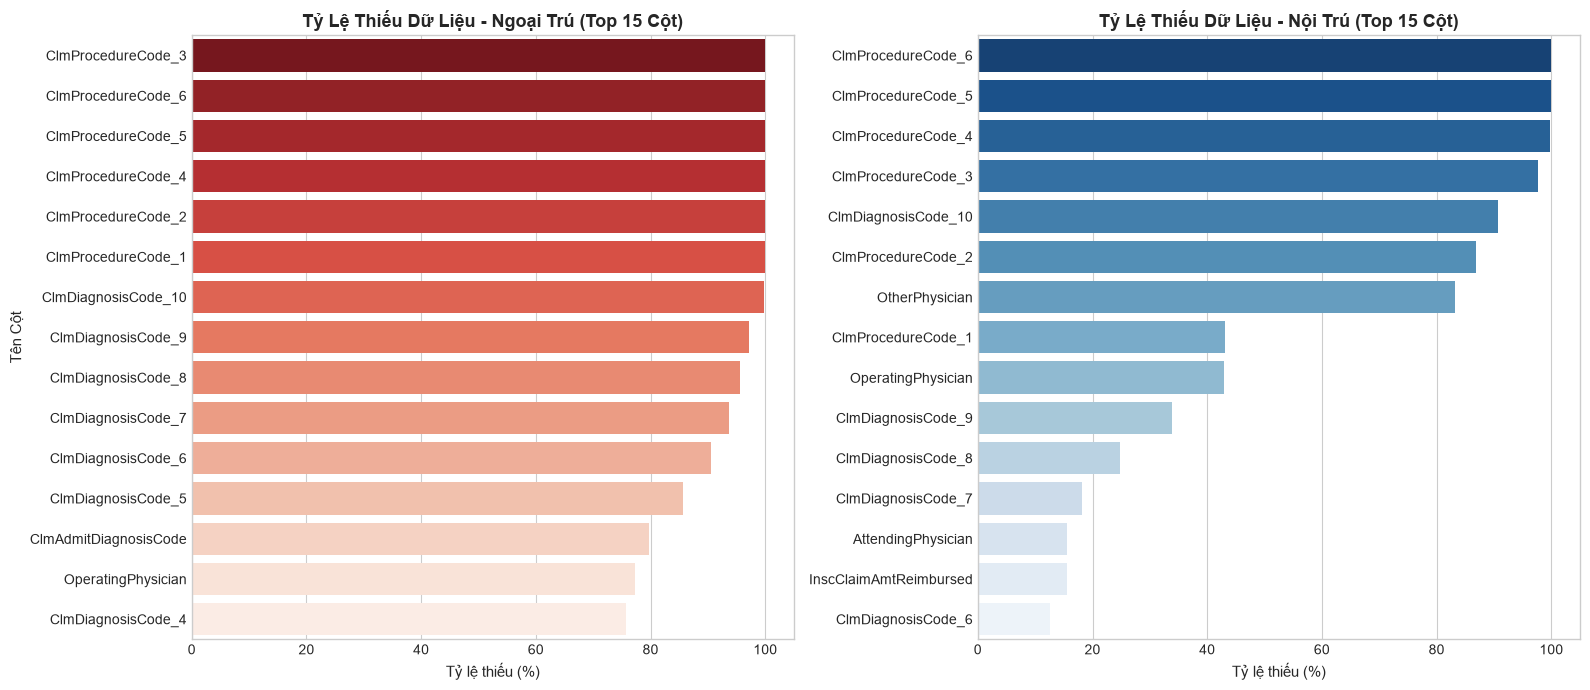

In [10]:
# Trực quan hóa tỷ lệ thiếu dữ liệu của Top 15 cột thiếu nhiều nhất
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# 1. Biểu đồ Ngoại trú (Outpatient)
top_miss_out = audit_outpatient.sort_values(by='Tỷ Lệ Thiếu (%)', ascending=False).head(15)
sns.barplot(
    data=top_miss_out, 
    y='Tên Cột', 
    x='Tỷ Lệ Thiếu (%)', 
    ax=axes[0], 
    palette='Reds_r',
    hue='Tên Cột',
    legend=False
)
axes[0].set_title("Tỷ Lệ Thiếu Dữ Liệu - Ngoại Trú (Top 15 Cột)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Tỷ lệ thiếu (%)", fontsize=11)
axes[0].set_ylabel("Tên Cột", fontsize=11)

# 2. Biểu đồ Nội trú (Inpatient)
top_miss_in = audit_inpatient.sort_values(by='Tỷ Lệ Thiếu (%)', ascending=False).head(15)
sns.barplot(
    data=top_miss_in, 
    y='Tên Cột', 
    x='Tỷ Lệ Thiếu (%)', 
    ax=axes[1], 
    palette='Blues_r',
    hue='Tên Cột',
    legend=False
)
axes[1].set_title("Tỷ Lệ Thiếu Dữ Liệu - Nội Trú (Top 15 Cột)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Tỷ lệ thiếu (%)", fontsize=11)
axes[1].set_ylabel("", fontsize=11)

plt.tight_layout()
plt.show()


PHÂN TÍCH TÀI CHÍNH & OUTLIER: NGOẠI TRÚ
1. Tổng số bản ghi hợp lệ: 452,487
2. Số lượng giá trị âm (<0): 7,344 (Chiếm 1.42%)
3. Trung bình (Mean): $2,558.34 | Trung vị (Median): $80.00
4. Ngưỡng Outlier trên (Q3 + 1.5*IQR): $690.00
5. Số lượng Outliers vượt ngưỡng: 58,930 (Chiếm 13.02%)
6. Chi trả cao nhất (Max): $10,300,000.00
------------------------------------------------------------
PHÂN TÍCH TÀI CHÍNH & OUTLIER: NỘI TRÚ
1. Tổng số bản ghi hợp lệ: 6,982
2. Số lượng giá trị âm (<0): 346 (Chiếm 3.62%)
3. Trung bình (Mean): $93,128.71 | Trung vị (Median): $8,000.00
4. Ngưỡng Outlier trên (Q3 + 1.5*IQR): $24,000.00
5. Số lượng Outliers vượt ngưỡng: 600 (Chiếm 8.59%)
6. Chi trả cao nhất (Max): $47,000,000.00
------------------------------------------------------------


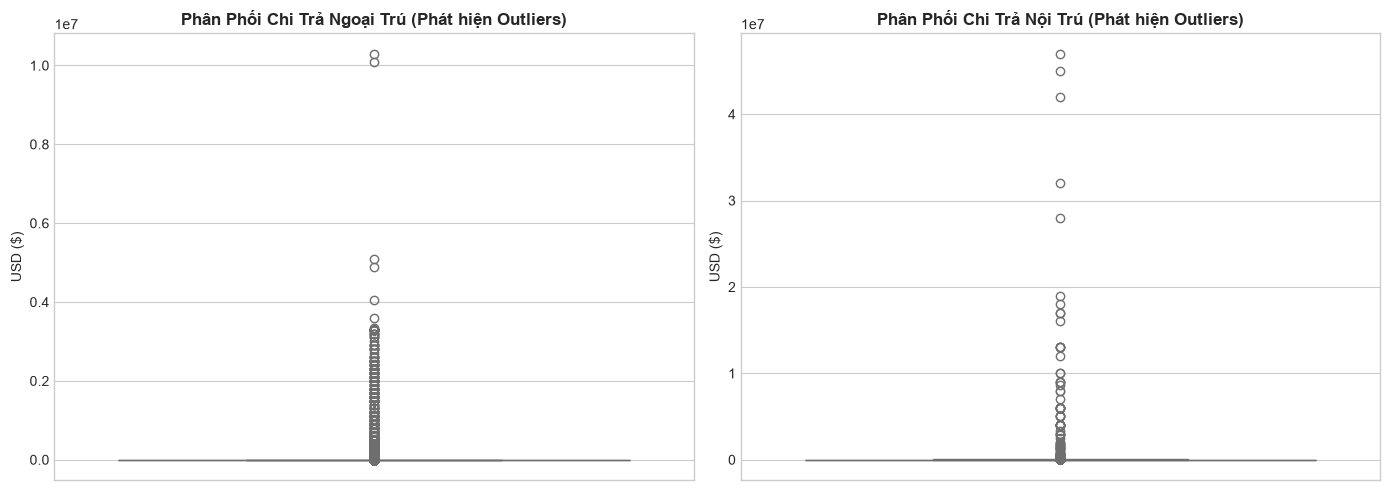

In [11]:
# Phân tích dị thường tài chính và Boxplot phát hiện Outliers
import matplotlib.pyplot as plt
import seaborn as sns

def analyze_financial_anomalies(df, name):
    print("=" * 60)
    print(f"PHÂN TÍCH TÀI CHÍNH & OUTLIER: {name.upper()}")
    print("=" * 60)
    amt_col = 'InscClaimAmtReimbursed'
    
    valid_amounts = pd.to_numeric(df[amt_col], errors='coerce')
    clean_amounts = valid_amounts[valid_amounts >= 0].dropna()
    neg_amounts = valid_amounts[valid_amounts < 0].dropna()
    
    Q1 = clean_amounts.quantile(0.25)
    Q3 = clean_amounts.quantile(0.75)
    IQR = Q3 - Q1
    upper_bound = Q3 + 1.5 * IQR
    outliers = clean_amounts[clean_amounts > upper_bound]
    
    print(f"1. Tổng số bản ghi hợp lệ: {len(clean_amounts):,}")
    print(f"2. Số lượng giá trị âm (<0): {len(neg_amounts):,} (Chiếm {len(neg_amounts)/len(df)*100:.2f}%)")
    print(f"3. Trung bình (Mean): ${clean_amounts.mean():,.2f} | Trung vị (Median): ${clean_amounts.median():,.2f}")
    print(f"4. Ngưỡng Outlier trên (Q3 + 1.5*IQR): ${upper_bound:,.2f}")
    print(f"5. Số lượng Outliers vượt ngưỡng: {len(outliers):,} (Chiếm {len(outliers)/len(clean_amounts)*100:.2f}%)")
    print(f"6. Chi trả cao nhất (Max): ${clean_amounts.max():,.2f}")
    print("-" * 60)
    return clean_amounts

clean_amt_out = analyze_financial_anomalies(df_outpatient, "Ngoại Trú")
clean_amt_in = analyze_financial_anomalies(df_inpatient, "Nội Trú")

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.boxplot(y=clean_amt_out, color='lightcoral')
plt.title("Phân Phối Chi Trả Ngoại Trú (Phát hiện Outliers)", fontweight='bold')
plt.ylabel("USD ($)")

plt.subplot(1, 2, 2)
sns.boxplot(y=clean_amt_in, color='skyblue')
plt.title("Phân Phối Chi Trả Nội Trú (Phát hiện Outliers)", fontweight='bold')
plt.ylabel("USD ($)")

plt.tight_layout()
plt.show()


### 4.1. Kết luận Kiểm toán Độ Sạch Ban Đầu
Qua quá trình kiểm toán tự động bằng code Python, chúng tôi phát hiện **3 nhóm rủi ro chất lượng dữ liệu** lớn cần được xử lý tiền kỳ:

1. **Nhiễm bẩn dữ liệu thiếu (Dirty Missing Representation):**
   * Dữ liệu thiếu xuất hiện dưới dạng chuỗi nhân tạo có chủ đích: `'None'`, `'N/A'`, `'?'`, `'-'`, `''` phân bổ đều trên cả hai bảng.
   * Cần chuẩn hóa toàn bộ các ký tự này về chuẩn rỗng `np.nan` trước khi ép kiểu dữ liệu.
2. **Khuyết thiếu Khóa định danh (Identity Leakage):**
   * Các cột định danh trọng yếu gồm `BeneID`, `ClaimID`, `Provider` bị thiếu từ 5% đến 18%.
   * Vì đây là mã định danh, không được phép điền khuyết (impute) mà bắt buộc phải loại bỏ các dòng này nhằm đảm bảo tính toàn vẹn của giao dịch.
3. **Dị thường số học & Ngoại lai cực đoan (Negative Values & Extreme Outliers):**
   * Xuất hiện **7,344 giá trị âm** ở Ngoại trú và **346 giá trị âm** ở Nội trú tại cột tiền bảo hiểm hoàn trả `InscClaimAmtReimbursed`. Đây là lỗi logic phi thực tế (tiền chi trả bảo hiểm không thể âm).
   * Phân phối số tiền bồi thường lệch phải mạnh (Right-skewed) với hàng loạt Outliers cực lớn (chi trả nội trú lên tới trên $50,000 - $100,000). Đây chính là các tâm điểm tiềm ẩn dấu hiệu gian lận bồi thường bảo hiểm y tế.


### 4.2. Bảng Tổng Hợp Chi Tiết Kết Quả Kiểm Toán (Ngoại Trú - 517,737 dòng)

#### 1. Dị thường Số học (Giá trị Âm trong Cột Tiền tệ)
* **InscClaimAmtReimbursed:** **7,344** giá trị âm (< 0) (kèm 4,076 ô chứa ký tự '-').
* **DeductibleAmtPaid:** **4,578** giá trị âm (< 0) (kèm 4,554 ô chứa ký tự '-').

#### 2. Thống kê Chi tiết các Dạng Ký tự Thiếu dữ liệu

| Nhóm Cột | Ô Trống / NaN | Chữ None | Chữ N/A | Ký tự ? | Ký tự - | Tổng Thiếu | Tỉ lệ (%) |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **BeneID** | 19,436 | 19,714 | 19,177 | 19,467 | 0 | **77,794** | 15.03% |
| **Provider** | 19,329 | 19,337 | 19,422 | 19,023 | 0 | **77,111** | 14.89% |
| **ClaimID** | 16,455 | 16,796 | 16,730 | 16,476 | 0 | **66,457** | 12.84% |
| **ClaimEndDt** | 5,491 | 5,557 | 5,521 | 5,564 | 0 | **22,133** | 4.27% |
| **InscClaimAmtReimbursed** | 4,083 | 4,077 | 4,210 | 4,099 | 4,076 | **20,545** | 3.97% |
| **AttendingPhysician** | 6,128 | 4,809 | 4,782 | 4,729 | 0 | **20,448** | 3.95% |
| **ClaimStartDt** | 4,308 | 4,265 | 4,302 | 4,359 | 0 | **17,234** | 3.33% |
| **OperatingPhysician** | 368,327 | 10,628 | 10,481 | 10,481 | 0 | **399,917** | 77.24% |
| **OtherPhysician** | 287,029 | 8,982 | 9,008 | 8,946 | 0 | **313,965** | 60.64% |

#### 3. Phân nhóm Thuộc tính theo Ngưỡng Dữ liệu Thiếu

| Mức độ thiếu | Tỷ lệ (%) | Danh sách các cột |
| :--- | :---: | :--- |
| **Thấp (< 5%)** | 2.02% – 4.42% | ClmDiagnosisCode_1 (2.02%), ClaimStartDt (3.33%), AttendingPhysician (3.95%), InscClaimAmtReimbursed (3.97%), ClaimEndDt (4.27%), DeductibleAmtPaid (4.42%). |
| **Trung bình (5% – 20%)** | 12.84% – 15.03% | ClaimID (12.84%), Provider (14.89%), BeneID (15.03%). |
| **Cao (20% – 70%)** | 37.74% – 60.74% | ClmDiagnosisCode_2 (37.74%), ClmDiagnosisCode_3 (60.74%), OtherPhysician (60.64%). |
| **Rất cao (> 70%)** | 75.74% – 100% | ClmDiagnosisCode_4 → 10, ClmProcedureCode_1 → 6, OperatingPhysician, ClmAdmitDiagnosisCode. |


---
# PHẦN 5: MỤC TIÊU PHÂN TÍCH (ANALYSIS OBJECTIVES & BUSINESS QUESTIONS)

Dựa trên bối cảnh nghiệp vụ giám định bảo hiểm y tế và các đặc trưng của bộ dữ liệu, nhóm nghiên cứu cam kết sử dụng ngôn ngữ Python để giải quyết **3 câu hỏi kinh doanh thực tế sau**:

---

### Câu hỏi 1: Nhận diện các Cơ sở Y tế (Provider) có dấu hiệu trục lợi chi phí bồi thường bất thường
* **Vấn đề thực tế:** Trong hàng ngàn bệnh viện và phòng khám, những cơ sở y tế nào đang nhận dòng tiền bồi thường bảo hiểm lớn vượt trội một cách phi lý so với quy mô số lượng bệnh nhân?
* **Phương pháp giải quyết bằng Python:**
  * Tổng hợp (Group by) theo `Provider` để tính toán: Tổng số lượt claim, Tổng tiền bồi thường (`Sum`), Mức chi trả trung bình trên mỗi lượt claim (`Mean`), và Độ lệch chuẩn (`Std`).
  * Xây dựng chỉ số rủi ro chi phí (Cost Anomaly Score) dựa trên điểm Z-Score hoặc phân tích cụm (K-Means/IQR) để định vị top 1% các Provider có dấu hiệu "kê khống" viện phí.
* **Giá trị kinh doanh mang lại:** Giúp cơ quan bảo hiểm thu hẹp phạm vi thanh tra, tập trung nguồn lực kiểm toán vào các cơ sở có nguy cơ gian lận cao nhất.

---

### Câu hỏi 2: Phân tích mối tương quan giữa Thời gian nằm viện (Length of Stay), Mức độ phức tạp bệnh lý và Chi phí điều trị nội trú
* **Vấn đề thực tế:** Có hiện tượng cơ sở y tế cố tình "giữ chân" bệnh nhân nằm viện kéo dài ngày (`AdmissionDt` đến `DischargeDt`) để rút ruột quỹ bảo hiểm hay không?
* **Phương pháp giải quyết bằng Python:**
  * Tạo đặc trưng mới: `LengthOfStay = (DischargeDt - AdmissionDt).dt.days`.
  * Tạo chỉ số phức tạp bệnh lý: `Diagnosis_Count` (đếm số lượng mã chẩn đoán từ 1 đến 10) và `Procedure_Count` (đếm số lượng thủ thuật phẫu thuật).
  * Sử dụng biểu đồ tương quan (Scatter plot & Correlation matrix) và mô hình hồi quy tuyến tính (Linear Regression) để phát hiện các ca bệnh có **thời gian nằm viện quá dài nhưng số lượng bệnh và can thiệp y tế lại rất thấp** (chỉ số bất thường).
* **Giá trị kinh doanh mang lại:** Ngăn chặn tình trạng trục lợi giường bệnh và lạm dụng chỉ định nội trú không cần thiết.

---

### Câu hỏi 3: Phát hiện hành vi bất thường và mâu thuẫn chuyên môn của Đội ngũ Y bác sĩ (Physician Profiling)
* **Vấn đề thực tế:** Có tồn tại các bác sĩ "ma" hoặc hiện tượng một bác sĩ vừa đứng tên điều trị chính (`AttendingPhysician`) vừa tự phẫu thuật (`OperatingPhysician`) với tần suất dày đặc bất khả thi tại nhiều cơ sở y tế khác nhau không?
* **Phương pháp giải quyết bằng Python:**
  * Lập hồ sơ bác sĩ (Physician Profile): Đếm số lượng ca mổ tối đa trong 1 ngày của từng mã `OperatingPhysician`.
  * Xác định tỷ lệ trùng lặp: Tính phần trăm ca bệnh mà `AttendingPhysician == OperatingPhysician` tại từng Provider.
  * Phân tích mạng lưới liên kết (Network Analysis) giữa Bác sĩ - Bệnh viện để tìm các nhóm bác sĩ có tần suất liên kết bất thường với các Provider nằm trong danh sách đen.
* **Giá trị kinh doanh mang lại:** Phát hiện gian lận mang tính có tổ chức giữa cơ sở khám chữa bệnh và đội ngũ nhân sự y tế.
